In [1]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    confusion_matrix
)

sns.set(style="whitegrid")

In [2]:
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

for root, _, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            file_path = os.path.join(root, file)
            break

df = pd.read_csv(file_path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.


In [3]:
df.drop("customerID", axis=1, inplace=True)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

/tmp/ipykernel_6746/3920077276.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)


In [4]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

cat_features = X.select_dtypes(include="object").columns
num_features = X.select_dtypes(exclude="object").columns

In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop="first"), cat_features)
    ]
)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),
    "Naive Bayes": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GaussianNB())
    ]),
    "SVM (RBF Kernel)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf", probability=True))
    ])
}

In [8]:
results = []
conf_matrices = {}
probabilities = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob)
    })

    conf_matrices[name] = confusion_matrix(y_test, y_pred)
    probabilities[name] = y_prob

results_df = pd.DataFrame(results)
print("\n=== Model Performance Comparison ===\n")
print(results_df)


=== Model Performance Comparison ===

                 Model  Accuracy  Precision    Recall  F1 Score       AUC
0  Logistic Regression  0.805536   0.657233  0.558824  0.604046  0.842006
1          Naive Bayes  0.655784   0.426877  0.866310  0.571933  0.809254
2     SVM (RBF Kernel)  0.792761   0.649635  0.475936  0.549383  0.792748


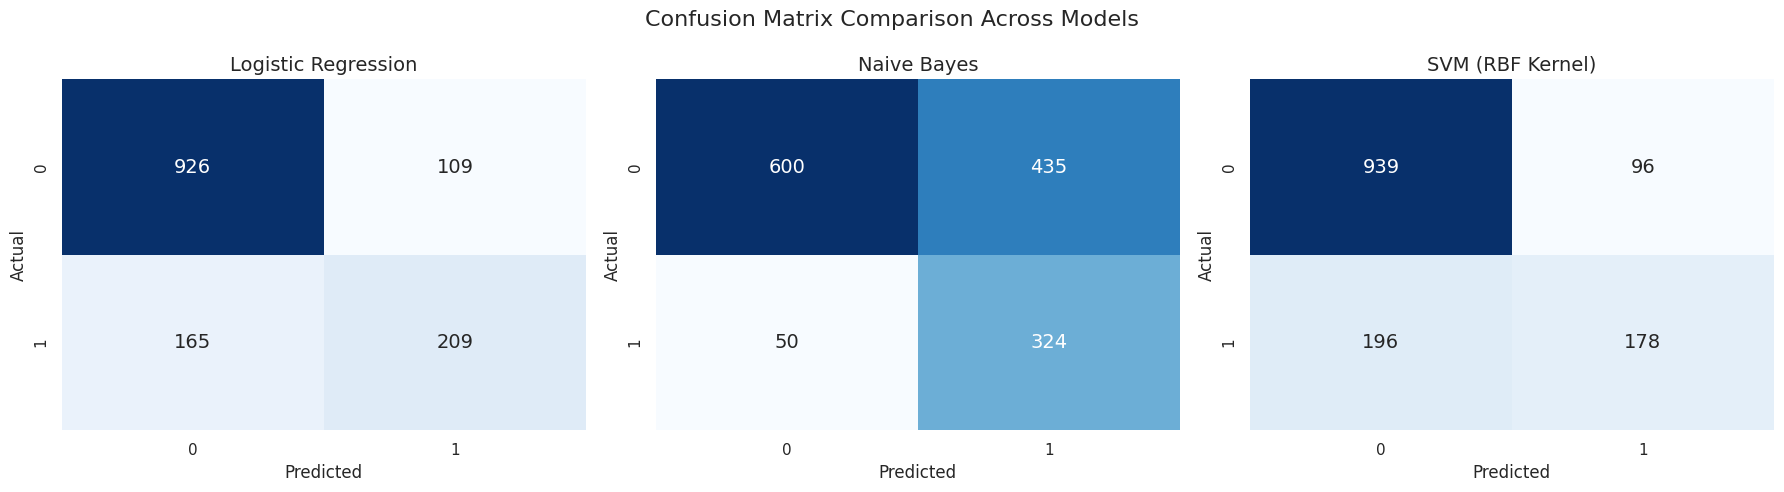

In [9]:
plt.figure(figsize=(18, 5))

for i, (model, cm) in enumerate(conf_matrices.items(), 1):
    plt.subplot(1, 3, i)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        annot_kws={"size": 14}
    )
    plt.title(model, fontsize=14)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

plt.suptitle("Confusion Matrix Comparison Across Models", fontsize=16)
plt.tight_layout()
plt.show()

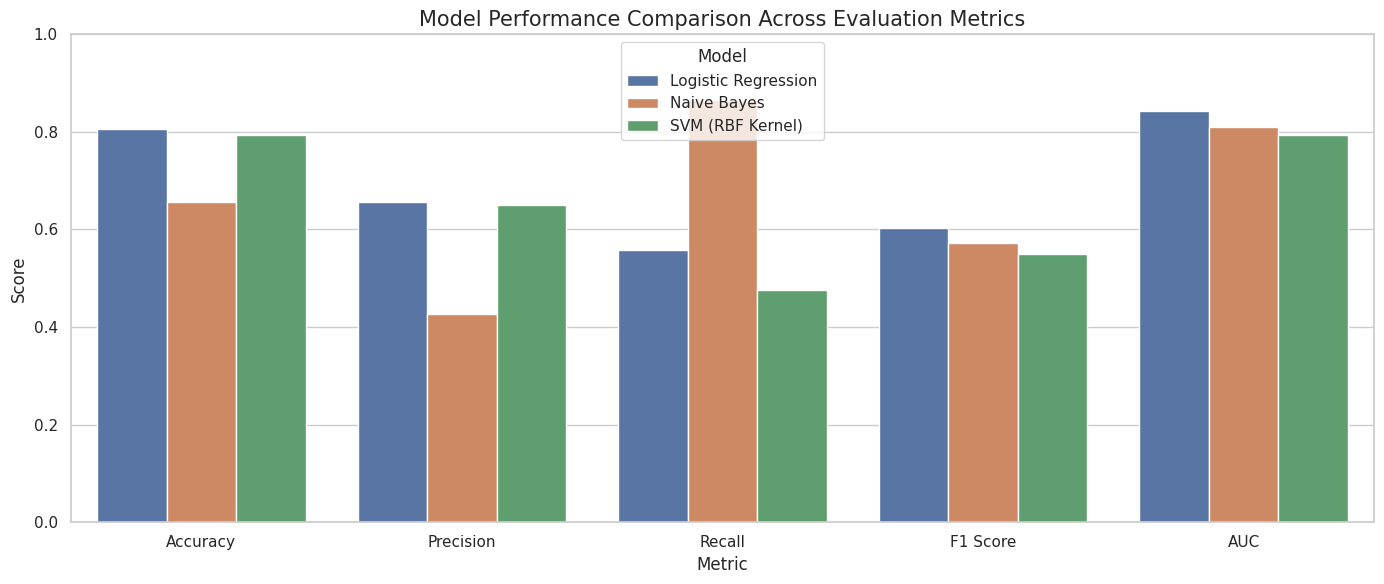

In [10]:
metrics_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 6))
sns.barplot(
    data=metrics_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Model Performance Comparison Across Evaluation Metrics", fontsize=15)
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()